In [1]:
import numpy as np
import pandas as pd
import torch
from sklearn import preprocessing
import matplotlib.pyplot as plt
import os

In [2]:
def get_taxonomy(file_path):
    """
    Parses a GBK file to check for the presence of 'Caudoviricetes'.
    Returns 'caudoviricetes' if found, else NaN.
    """
    try:
        with open(file_path, 'r') as f:
            content = f.read()
            # Check if the specific word exists in the file content
            if 'Caudoviricetes' in content:
                return 'caudoviricetes'
    except FileNotFoundError:
        return np.nan
    except Exception as e:
        print(f"Error reading {file_path}: {e}")
        return np.nan
    
    return np.nan

In [3]:
# Load the file using the path exactly as it was saved
file_path = 'embeddings_171225_2176_32768_blocks.28.mlp.l3' 
# file_path = 'embeddings_291225_2176_32768_blocks.28.mlp.l3_32768.pt'
data = torch.load(file_path, map_location=torch.device('cpu'))

# Extract the lists from the dictionary
ids = data["ids"]               # List of strings
# DeepPL files contains accession id without version number, so we need to erase it from our ids
ids = [item.split('.')[0] for item in ids] 
embeddings_list = data["embeddings"] # List of torch.Tensors

# Stack the list of tensors into one large tensor (N_samples x 4096)
embeddings_tensor = torch.stack(embeddings_list)

# Convert to Numpy array
loaded_embeds = embeddings_tensor.detach().cpu().numpy()
loaded_ids = np.array(ids)

print("Embeddings shape:", loaded_ids.shape)
print("Embeddings shape:", loaded_embeds.shape) 

df = pd.DataFrame(data=loaded_embeds[:,:],    # values
              index=loaded_ids[:],    # 1st column as index
              columns=[[f"feature_{i}" for i in range(len(loaded_embeds[0]))]]) 
# Take a look
df.head()

Embeddings shape: (2176,)
Embeddings shape: (2176, 4096)


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_4086,feature_4087,feature_4088,feature_4089,feature_4090,feature_4091,feature_4092,feature_4093,feature_4094,feature_4095
NC_012663,190.00,-378.0,-284.0,376.0,420.0000,-162.000,-472.0,171.00,-314.0,-1024.0,...,-170.000,134.0000,-246.0,-264.00,-260.00,322.000,350.0,-456.0,-266.00,-30.250
NC_025467,58.25,-94.0,-83.5,96.5,103.0000,-48.750,-115.5,43.75,-69.0,-276.0,...,-51.000,38.0000,-58.0,-56.75,-55.50,100.000,83.0,-121.0,-23.75,-24.125
AJ298298,80.00,-170.0,-140.0,364.0,-11.3125,-48.500,-360.0,41.75,-230.0,-392.0,...,-57.000,28.5000,-119.5,-111.50,-72.00,28.375,81.0,-306.0,-132.00,-10.875
NC_025436,580.00,-868.0,-556.0,840.0,904.0000,-276.000,-1000.0,364.00,-676.0,-2160.0,...,-438.000,318.0000,-516.0,-656.00,-524.00,912.000,936.0,-1080.0,38.00,-164.000
NC_018269,47.00,-79.0,-82.0,88.0,35.0000,-11.375,-112.5,28.00,-93.5,-171.0,...,-29.125,12.3125,-69.5,-52.25,-54.25,45.500,81.5,-107.0,-55.75,-21.375


In [4]:
# Training
sheet_names = pd.ExcelFile("journal.pcbi.1012525.s001.xlsx").sheet_names
# Training dataset
training = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[0])
# Test dataset
test = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[1])
# Path to gbk folder
gbk_directory = "data_gbk/"

# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life

aligned_lifecycles = []     # Create aligned list of lifecycles
taxonomy_list = []      # Caudovirales list
for accession in df.index:
    if accession in lifecycle_map:
        gbk_file_path = os.path.join(gbk_directory, f"{accession}.gbk")
        aligned_lifecycles.append(lifecycle_map[accession])
        tax = get_taxonomy(gbk_file_path)
        taxonomy_list.append(tax)
    else:
        # Warning only once per missing ID to avoid clutter
        print(f"Warning: Accession {accession} not found. Defaulting to lytic.")
        aligned_lifecycles.append("lytic")
        taxonomy_list.append(np.nan)

aligned_lifecycles = np.array(aligned_lifecycles)
print(f"Aligned labels length: {len(aligned_lifecycles)}")

Aligned labels length: 2176


In [5]:
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
import pandas as pd
import numpy as np

# Set global random state
RANDOM_STATE = 0

# Create a separate DataFrame just for metadata to avoid MultiIndex issues with 'df'
# Ensure 'taxonomy_list' and 'aligned_lifecycles' are aligned with df.index
metadata_df = pd.DataFrame({
    'taxonomy': taxonomy_list,
    'lifecycle': aligned_lifecycles
}, index=df.index)

# Get indices where taxonomy is 'caudoviricetes'
# We use boolean masking on the metadata dataframe
caudo_mask = metadata_df['taxonomy'] == 'caudoviricetes'
caudo_metadata = metadata_df[caudo_mask]

print(f"Total Caudovirales samples found: {len(caudo_metadata)}")

# Identify indices for each class within the filtered Caudovirales set
lytic_indices = caudo_metadata[caudo_metadata['lifecycle'] == 'lytic'].index
lysogenic_indices = caudo_metadata[caudo_metadata['lifecycle'] == 'lysogenic'].index

print(f"Lytic count: {len(lytic_indices)}, Lysogenic count: {len(lysogenic_indices)}")

# Find the count of the minority class
min_count = min(len(lytic_indices), len(lysogenic_indices))

if min_count == 0:
    raise ValueError("One of the classes has 0 samples! Check your taxonomy/lifecycle parsing.")

print(f"Balancing dataset to {min_count} samples per class.")

# Randomly sample indices
lytic_sampled_indices = np.random.choice(lytic_indices, min_count, replace=False)
lysogenic_sampled_indices = np.random.choice(lysogenic_indices, min_count, replace=False)

# Combine and shuffle indices
balanced_indices = np.concatenate([lytic_sampled_indices, lysogenic_sampled_indices])
np.random.shuffle(balanced_indices)

# Use the safe indices to extract X from the original df and y from metadata
# .loc ensures we get the exact rows corresponding to our balanced selection
X = df.loc[balanced_indices].values
y = caudo_metadata.loc[balanced_indices, 'lifecycle'].values

# Verification: Check for NaNs in X or y
if pd.isna(X).any():
    print("WARNING: X contains NaNs. Filling with 0 (or handle as needed).")
    X = np.nan_to_num(X)
if pd.isna(y).any():
    raise ValueError("Error: y contains NaNs! Check the alignment of lifecycle lists.")

# Stratify ensures 50/50 balance in both Train and Test sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=y
)

# Scale data
scaler = preprocessing.StandardScaler()
scaler.fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)


print("-" * 30)
print(f"Final Training Set: {X_train.shape[0]} samples")
print(f"Final Test Set: {X_test.shape[0]} samples")

unique_train, counts_train = np.unique(y_train, return_counts=True)
print(f"Train Class Distribution: {dict(zip(unique_train, counts_train))}")

unique_test, counts_test = np.unique(y_test, return_counts=True)
print(f"Test Class Distribution: {dict(zip(unique_test, counts_test))}")

Total Caudovirales samples found: 2029
Lytic count: 1357, Lysogenic count: 672
Balancing dataset to 672 samples per class.
------------------------------
Final Training Set: 1075 samples
Final Test Set: 269 samples
Train Class Distribution: {'lysogenic': np.int64(537), 'lytic': np.int64(538)}
Test Class Distribution: {'lysogenic': np.int64(135), 'lytic': np.int64(134)}


In [6]:
import numpy as np
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score, 
                             matthews_corrcoef, make_scorer)
from sklearn.model_selection import TunedThresholdClassifierCV
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# We tell the tuner: "Find the threshold that maximizes F1 score for 'lysogenic'"
f1_scorer = make_scorer(f1_score, pos_label="lysogenic")

# Define function to print metrics for each model
def compute_and_print_metrics(model_name, y_true, y_pred, pos_label="lysogenic"):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, pos_label=pos_label)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    neg_label = "lytic" if pos_label == "lysogenic" else "lysogenic"
    cm = confusion_matrix(y_true, y_pred, labels=[neg_label, pos_label])
    tn, fp, fn, tp = cm.ravel()
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    print(f"\n{model_name} RESULTS")
    print("-" * 30)
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity:          {specificity:.4f}")
    print(f"Accuracy:             {acc:.4f}")
    print(f"F1-Score:             {f1:.4f}")
    print(f"MCC:                  {mcc:.4f}")
    print("-" * 30)
    print("Confusion Matrix:")
    print(f"                 Pred {neg_label}  Pred {pos_label}")
    print(f"Actual {neg_label:9} {tn:5d}           {fp:5d}")
    print(f"Actual {pos_label:9} {fn:5d}           {tp:5d}")


### Logistic Regression

In [7]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {
    'C' : np.logspace(-4,4,10),
    'solver': ['lbfgs','liblinear'],
}
]
# Initialize base model (balanced weights are crucial here)
lr_base = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE, class_weight='balanced')
# GridSearch tries all combinations in param_grid
# We use the same scoring (f1_scorer) to pick the best params
grid_search = GridSearchCV(
    lr_base, 
    param_grid, 
    cv=5, 
    scoring=f1_scorer, 
    n_jobs=-1,  # Use all CPU cores
    verbose=1
)


print("Starting Grid Search...")
grid_search.fit(X_train, y_train)

best_lr_model = grid_search.best_estimator_
print(f"Best Hyperparameters found: {grid_search.best_params_}")


# Now we take the optimized model and fine-tune the decision threshold
# TunedThresholdClassifierCV will use internal CV to find the cutoff
lr_tuned = TunedThresholdClassifierCV(best_lr_model, scoring=f1_scorer, cv=5)
lr_tuned.fit(X_train, y_train)

print(f"LR Optimal Threshold: {lr_tuned.best_threshold_:.3f}")

# This uses the Best Hyperparameters AND the Best Threshold
y_pred_lr = lr_tuned.predict(X_test)

compute_and_print_metrics("LOGISTIC REGRESSION (GridSearch + Tuned Threshold)", y_test, y_pred_lr)

Starting Grid Search...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Hyperparameters found: {'C': np.float64(166.81005372000558), 'solver': 'liblinear'}
LR Optimal Threshold: 0.545

LOGISTIC REGRESSION (GridSearch + Tuned Threshold) RESULTS
------------------------------
Sensitivity (Recall): 0.9185
Specificity:          0.9030
Accuracy:             0.9108
F1-Score:             0.9118
MCC:                  0.8216
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       121              13
Actual lysogenic    11             124


### Random Forest

Starting Random Forest Grid Search...
Fitting 5 folds for each of 135 candidates, totalling 675 fits
Best RF Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 400}
RF Optimal Threshold: 0.444

RANDOM FOREST (GridSearch + Tuned Threshold) RESULTS
------------------------------
Sensitivity (Recall): 0.9556
Specificity:          0.8955
Accuracy:             0.9257
F1-Score:             0.9281
MCC:                  0.8528
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       120              14
Actual lysogenic     6             129


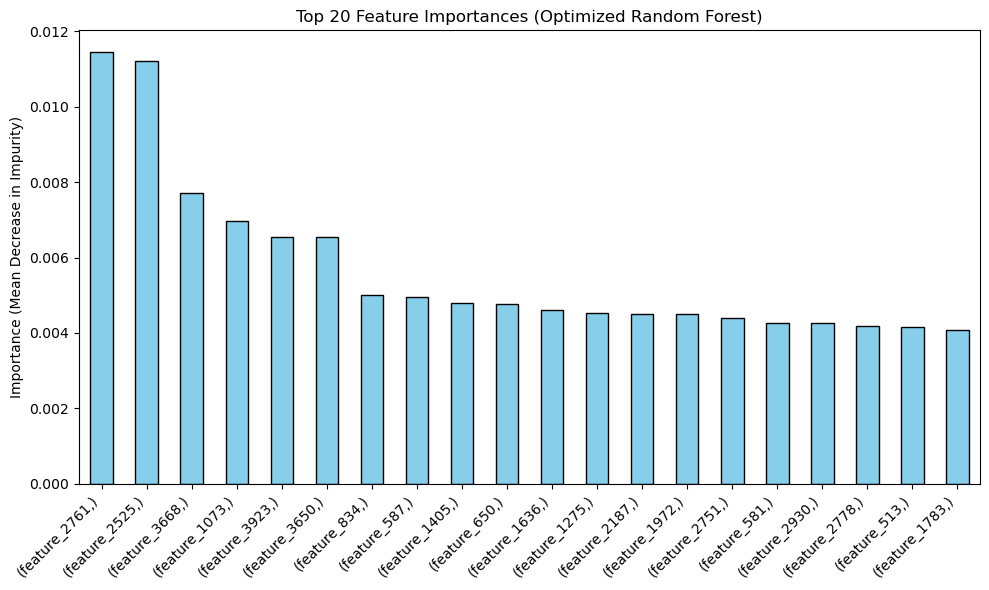

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import pandas as pd

# --- 1. SETUP PARAMETER GRID ---
# These are the most critical parameters to tune for Random Forest
param_grid_rf = {
    'n_estimators': [100, 200, 300, 400, 500],        # Number of trees (more is stable but slower)
    'max_depth': [None, 10, 20],       # Depth of tree (None = fully grown)
    'min_samples_split': [2, 5, 10],   # Min samples to create a split
    'min_samples_leaf': [1, 2, 4]      # Min samples required at a leaf node
}

# --- 2. RUN HYPERPARAMETER TUNING (GridSearchCV) ---
# Initialize base model with balanced weights
rf_base = RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced')

# GridSearch finds the best combination of parameters
grid_search_rf = GridSearchCV(
    rf_base, 
    param_grid_rf, 
    cv=5, 
    scoring=f1_scorer, 
    n_jobs=4,  # Use all available CPU cores
    verbose=1
)

print("Starting Random Forest Grid Search...")
grid_search_rf.fit(X_train, y_train)

best_rf_model = grid_search_rf.best_estimator_
print(f"Best RF Parameters: {grid_search_rf.best_params_}")

# Now tune the decision threshold using the optimized model
rf_tuned = TunedThresholdClassifierCV(best_rf_model, scoring=f1_scorer, cv=5)
rf_tuned.fit(X_train, y_train)

print(f"RF Optimal Threshold: {rf_tuned.best_threshold_:.3f}")

# Predict and evaluate on test set
y_pred_rf = rf_tuned.predict(X_test)
compute_and_print_metrics("RANDOM FOREST (GridSearch + Tuned Threshold)", y_test, y_pred_rf)


# See which biological features mattered most to the optimized model
importances = best_rf_model.feature_importances_
# If X_train was a DataFrame, use X_train.columns. If not, use indices or your original df.columns
feature_names = df.columns if hasattr(df, 'columns') else [f"Feature {i}" for i in range(X_train.shape[1])]

forest_importances = pd.Series(importances, index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
forest_importances.head(20).plot.bar(ax=ax, color='skyblue', edgecolor='black')
ax.set_title("Top 20 Feature Importances (Optimized Random Forest)")
ax.set_ylabel("Importance (Mean Decrease in Impurity)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### XGBoost (sklearn)

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, TunedThresholdClassifierCV
from sklearn.metrics import make_scorer, f1_score

param_grid_hgb = {
    'learning_rate': [0.01, 0.1, 0.2],  # Step size
    'max_iter': [100, 200, 500, 1000],             # Number of trees
    'max_depth': [3, 5, 10],            # Depth (None is also allowed for leaf-wise growth)
    'l2_regularization': [0.0, 0.1, 1] # Regularization to prevent overfitting
}

# We use class_weight='balanced' natively (no manual calculation needed)
hgb_base = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=RANDOM_STATE,
    scoring='loss' # Optimizes log-loss internally
)

# Define Scorer (Optimizing F1 for Lysogenic)
# Since HistGradientBoosting accepts strings, we don't strictly need LabelEncoder for y,
# but using the scorer with pos_label ensures clarity.
scorer = make_scorer(f1_score, pos_label="lysogenic")

print("Starting HistGradientBoosting Grid Search...")
grid_search_hgb = GridSearchCV(
    hgb_base, 
    param_grid_hgb, 
    cv=5, 
    scoring=scorer, 
    n_jobs=-1, # Adjust based on your available cores
    verbose=1
)

grid_search_hgb.fit(X_train, y_train)

best_hgb = grid_search_hgb.best_estimator_
print(f"Best HGB Params: {grid_search_hgb.best_params_}")

# --- 3. RUN THRESHOLD TUNING ---
# Tune decision threshold on the optimized model
print("Tuning Decision Threshold...")
hgb_final = TunedThresholdClassifierCV(best_hgb, scoring=scorer, cv=5)
hgb_final.fit(X_train, y_train)

print(f"HGB Optimal Threshold: {hgb_final.best_threshold_:.3f}")

# --- 4. PREDICT & EVALUATE ---
# HistGradientBoosting in sklearn handles string labels natively!
y_pred_hgb = hgb_final.predict(X_test)

compute_and_print_metrics("HistGradientBoosting (Sklearn's XGBoost)", y_test, y_pred_hgb)

Starting HistGradientBoosting Grid Search...
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best HGB Params: {'l2_regularization': 0.0, 'learning_rate': 0.2, 'max_depth': 5, 'max_iter': 500}
Tuning Decision Threshold...
HGB Optimal Threshold: 0.455

HistGradientBoosting (Sklearn's XGBoost) RESULTS
------------------------------
Sensitivity (Recall): 0.9185
Specificity:          0.9104
Accuracy:             0.9145
F1-Score:             0.9151
MCC:                  0.8290
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       122              12
Actual lysogenic    11             124


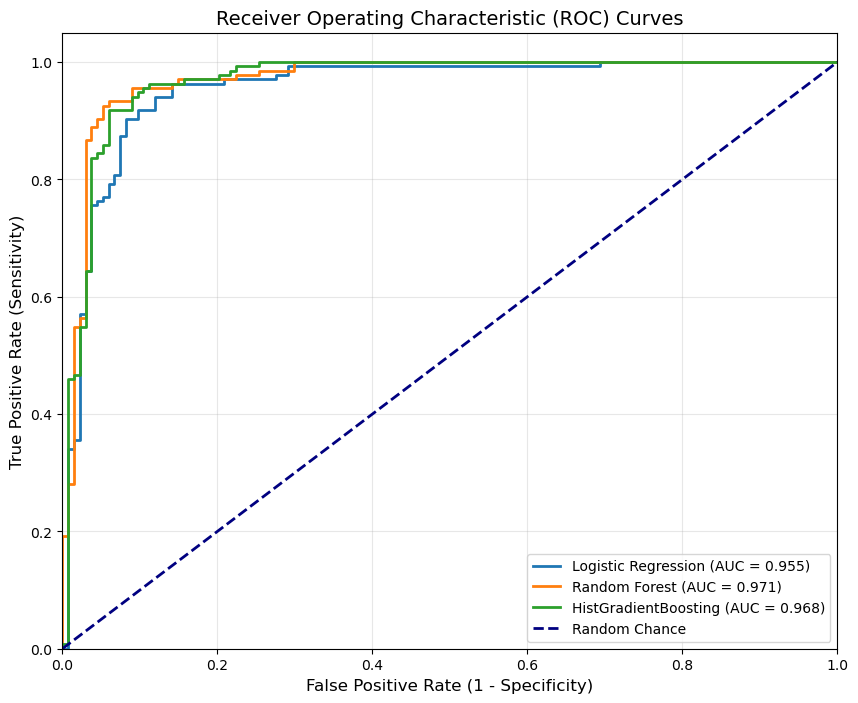

In [10]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# # 1. Define the models you want to plot
# best_lr_model = LogisticRegression(
#     max_iter=5000, 
#     random_state=RANDOM_STATE, 
#     class_weight='balanced', 
#     C=0.3593813663804626,
#     solver='lbfgs'
# )
# # Best RF Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
# best_rf_model = rf_base = RandomForestClassifier(
#     random_state=RANDOM_STATE, 
#     class_weight='balanced', 
#     max_depth=10,
#     min_samples_leaf=4,
#     min_samples_split=2, 
#     n_estimators=100
# )

# best_hgb = HistGradientBoostingClassifier(
#     class_weight='balanced',
#     random_state=0,
#     scoring='loss',
#     l2_regularization=1,
#     learning_rate=0.01,
#     max_depth=3,
#     max_iter=1000
# )

models_dict = {
    "Logistic Regression": best_lr_model,
    "Random Forest": best_rf_model,
    "HistGradientBoosting": best_hgb
}

plt.figure(figsize=(10, 8))

for name, model in models_dict.items():
    # Check if the model is fitted; if not, print a warning and skip
    if not hasattr(model, "classes_"):
        print(f"Warning: Model '{name}' appears to be unfitted (missing 'classes_'). Skipping.")
        continue

    # Identify the index of the positive class ('lysogenic')
    pos_label = "lysogenic"
    # TunedThresholdClassifierCV exposes classes_ from the underlying estimator
    if pos_label in model.classes_:
        pos_idx = list(model.classes_).index(pos_label)
    else:
        pos_idx = 1 
    
    # Get predicted probabilities
    # Note: TunedThresholdClassifierCV.predict_proba delegates to the underlying estimator
    y_proba = model.predict_proba(X_test)[:, pos_idx]
    
    # Calculate ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_proba, pos_label=pos_label)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

# Formatting the plot
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.show()